<a href="https://colab.research.google.com/github/LuisTT0903/Processamento-de-Sinais1/blob/main/Aula_08/Pratica8Quest%C3%A3o2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Erro máximo entre h_d analítico e h_d numérico (M = 100):
  (a) Escada: 2 até π/6, 1 até π/3: 1.67e-06
  (b) Triangular: 1 − |ω|/(2ωc), ωc = π/3: 4.17e-12
  (c) Trapezoidal: rampa 0→π/4, plano até π/2: 2.50e-06


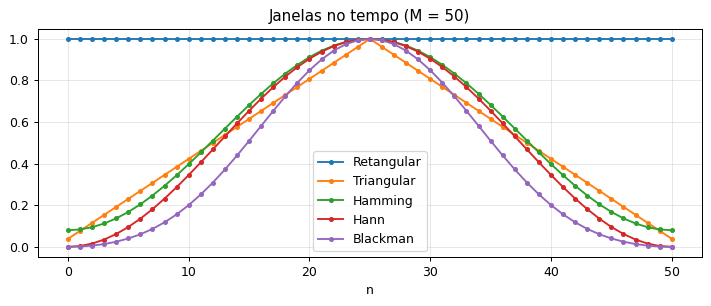

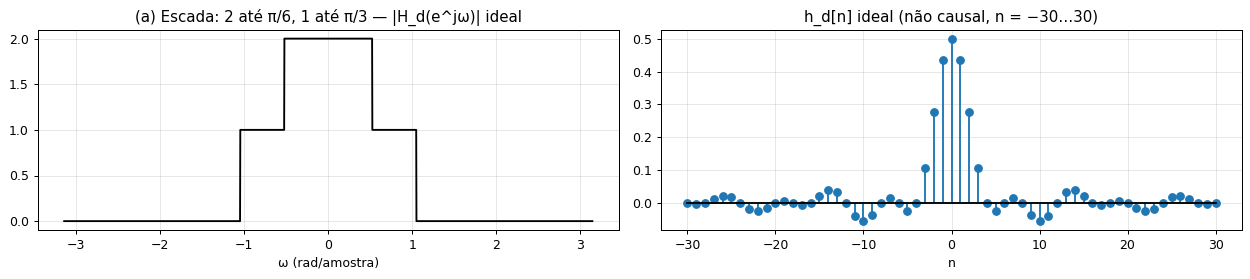

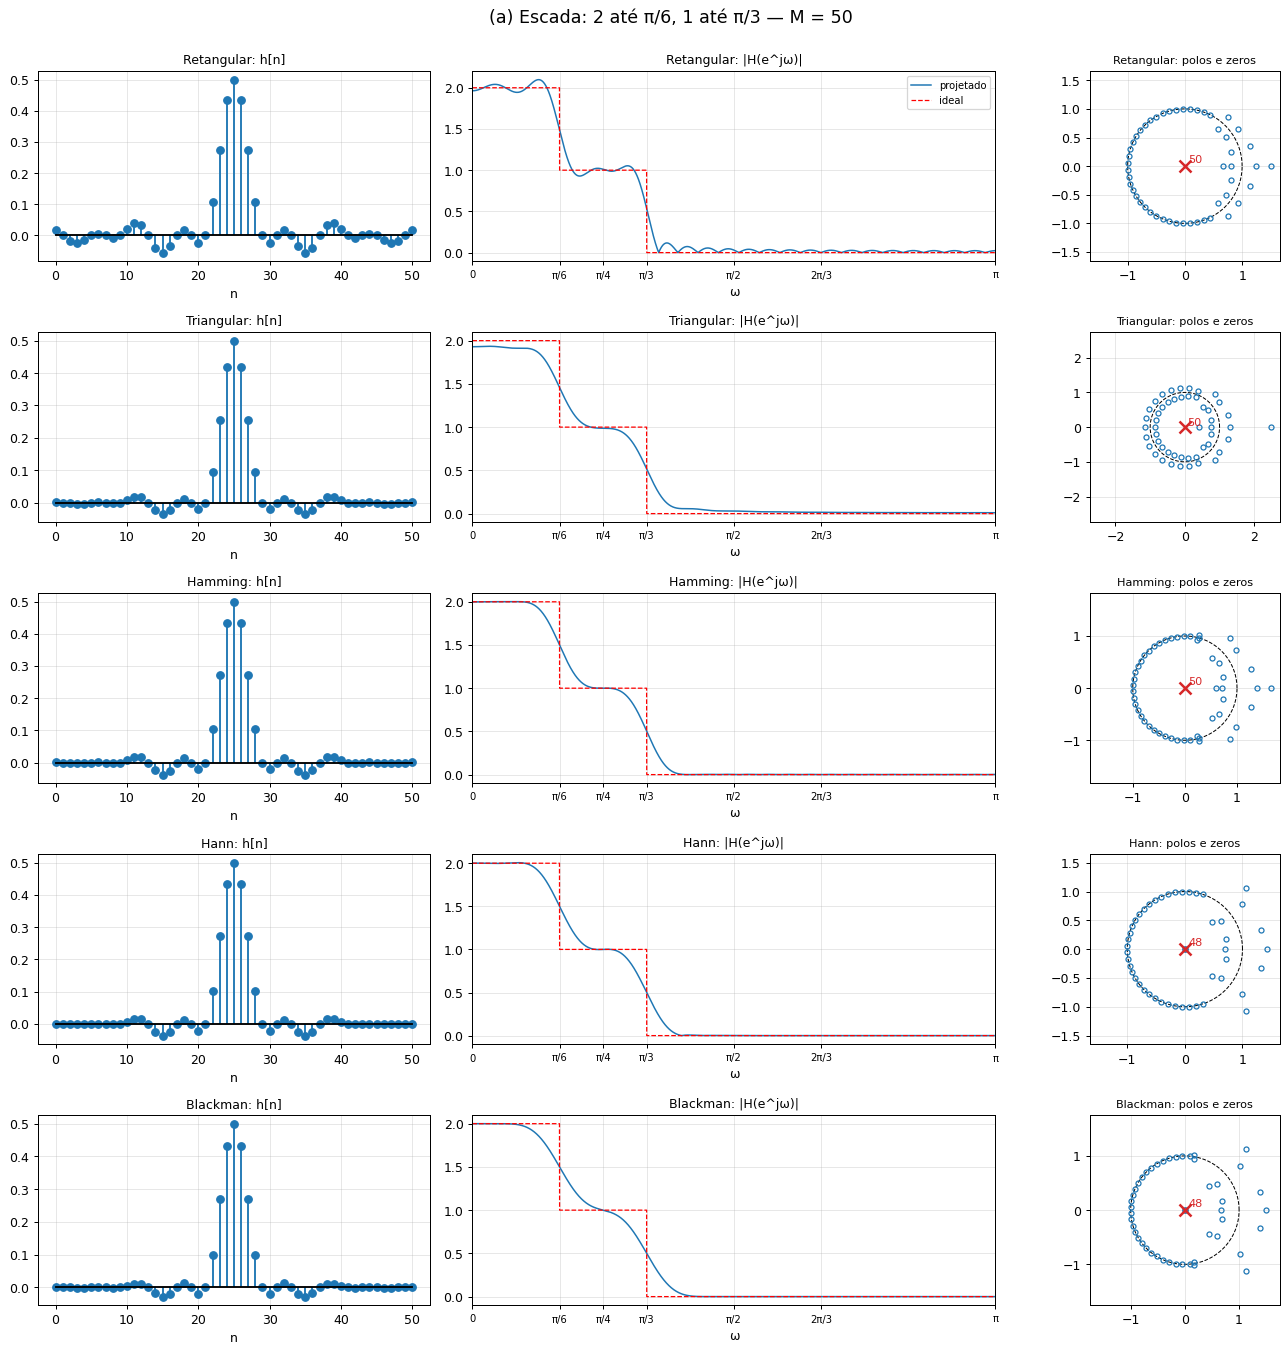

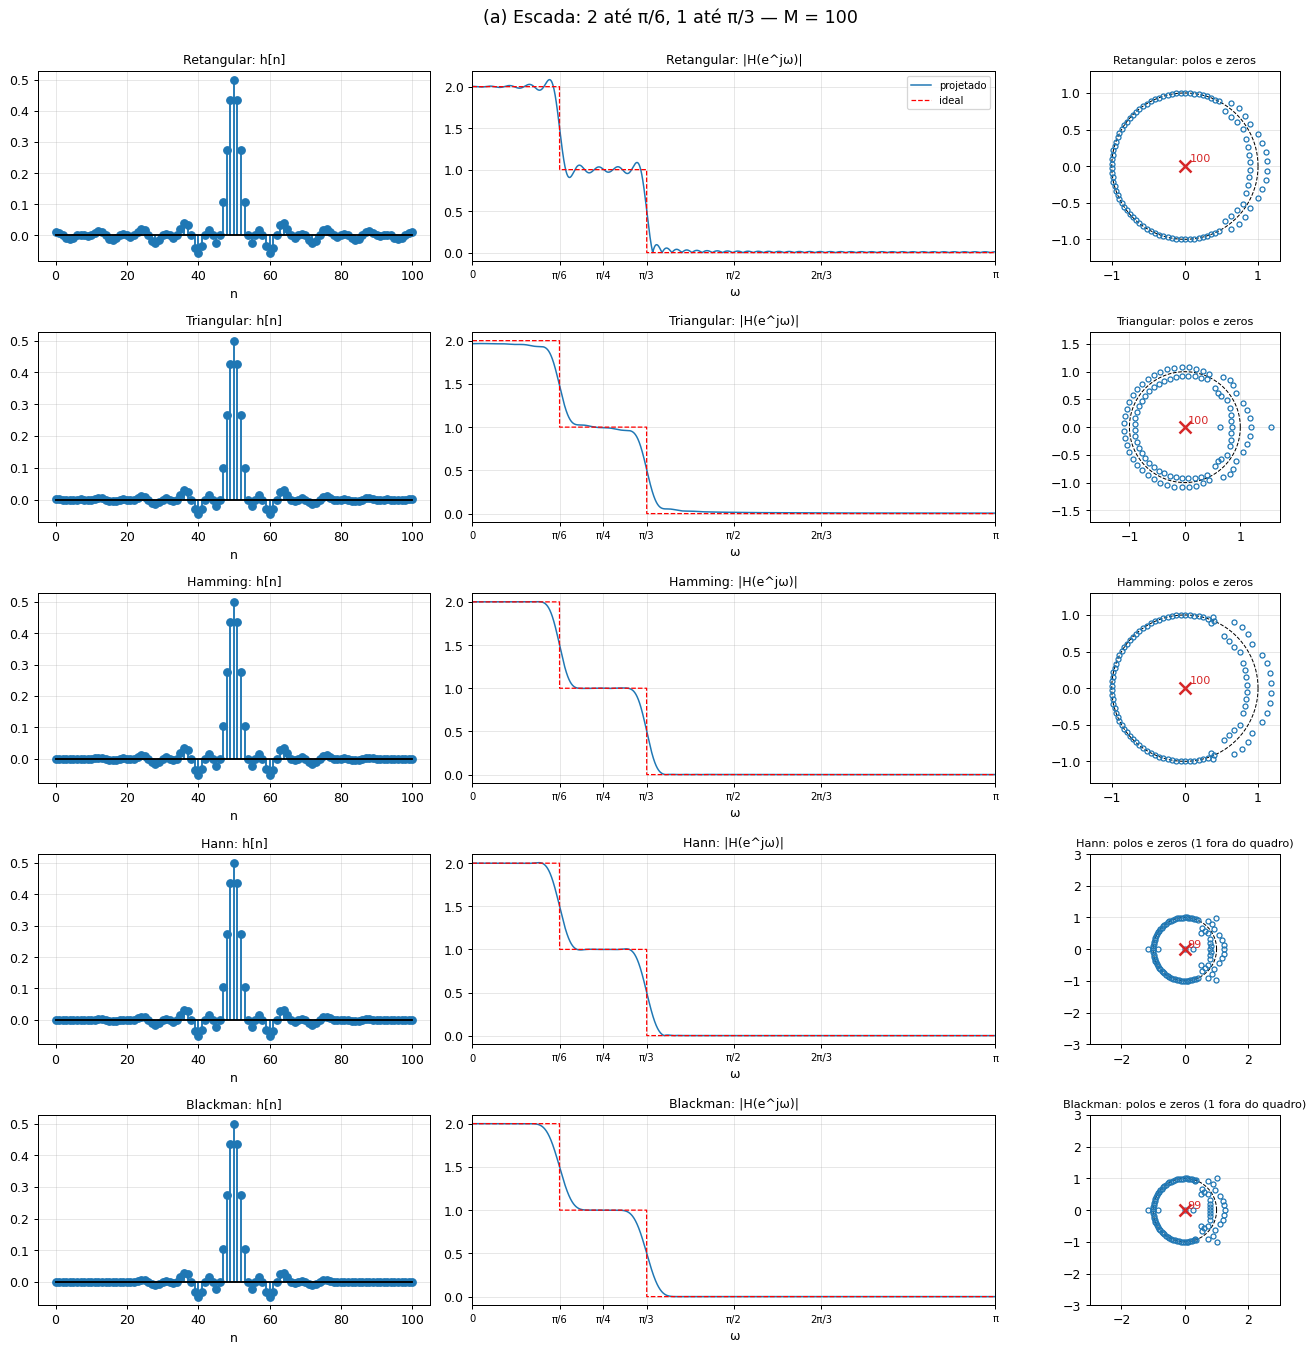

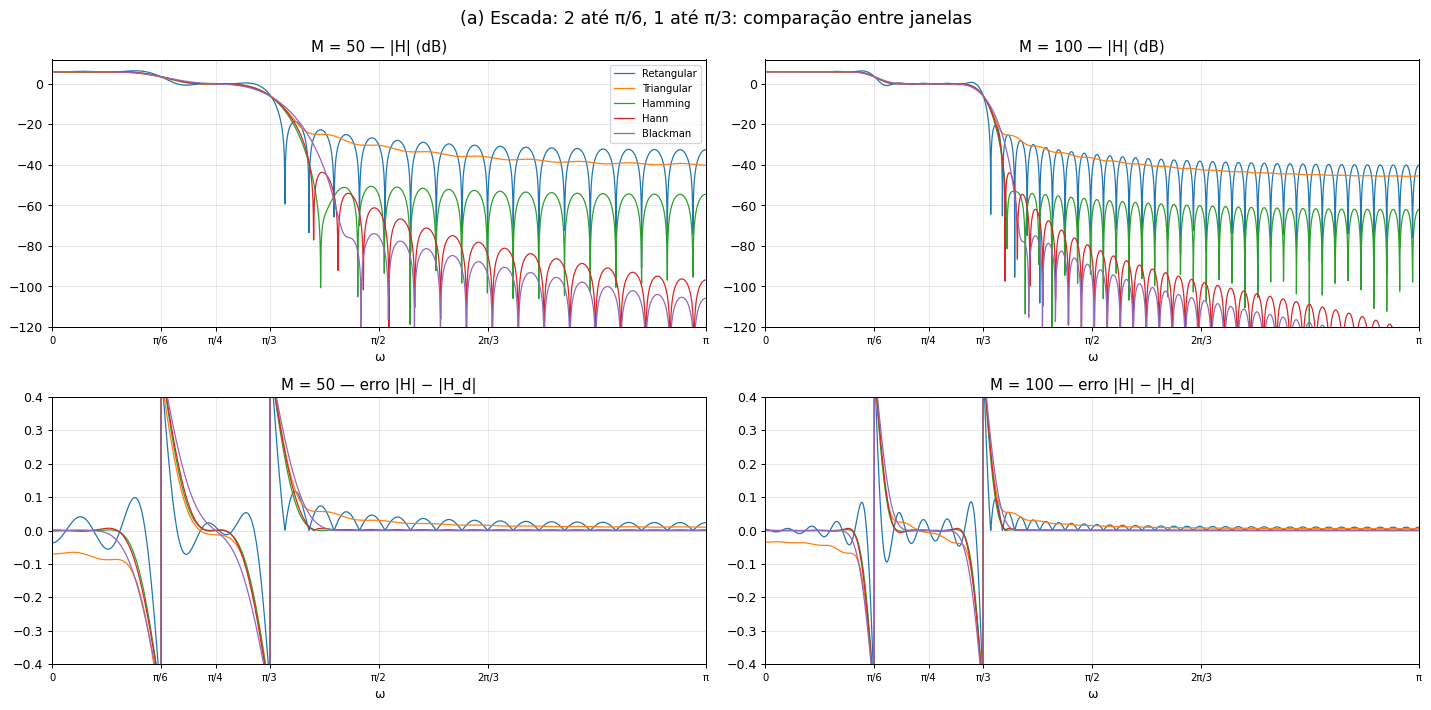

(a) Resultados:


|H| em ω=0  |H| em ω=π/12  |H| em ω=π/4  |H| em ω=π/2  \
M   Janela                                                              
50  Retangular       1.963          1.945         1.011         0.030   
    Triangular       1.930          1.913         0.987         0.030   
    Hamming          1.998          2.002         1.001         0.002   
    Hann             2.001          2.006         1.000         0.001   
    Blackman         2.000          1.992         1.000         0.000   
100 Retangular       2.004          1.991         1.006         0.007   
    Triangular       1.965          1.956         0.994         0.015   
    Hamming          2.000          2.000         1.000         0.001   
    Hann             2.000          2.001         1.000         0.000   
    Blackman         2.000          2.000         1.000         0.000   

                Erro máx. (fora das transições)  Rejeição máx. (dB)  
M   Janela                                                           
50  Retangular                            0.072               -22.8  
    Triangular                            0.087               -24.9  
    Hamming                               0.003               -50.6  
    Hann                                  0.007               -43.7  
    Blackman                              0.011               -39.1  
100 Retangular                            0.028               -31.2  
    Triangular                            0.044               -30.7  
    Hamming                               0.002               -54.6  
    Hann                                  0.001               -61.9  
    Blackman                              0.000               -75.0

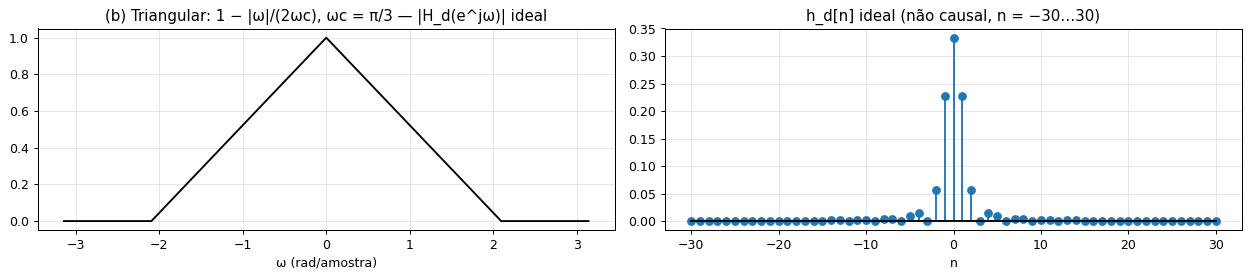

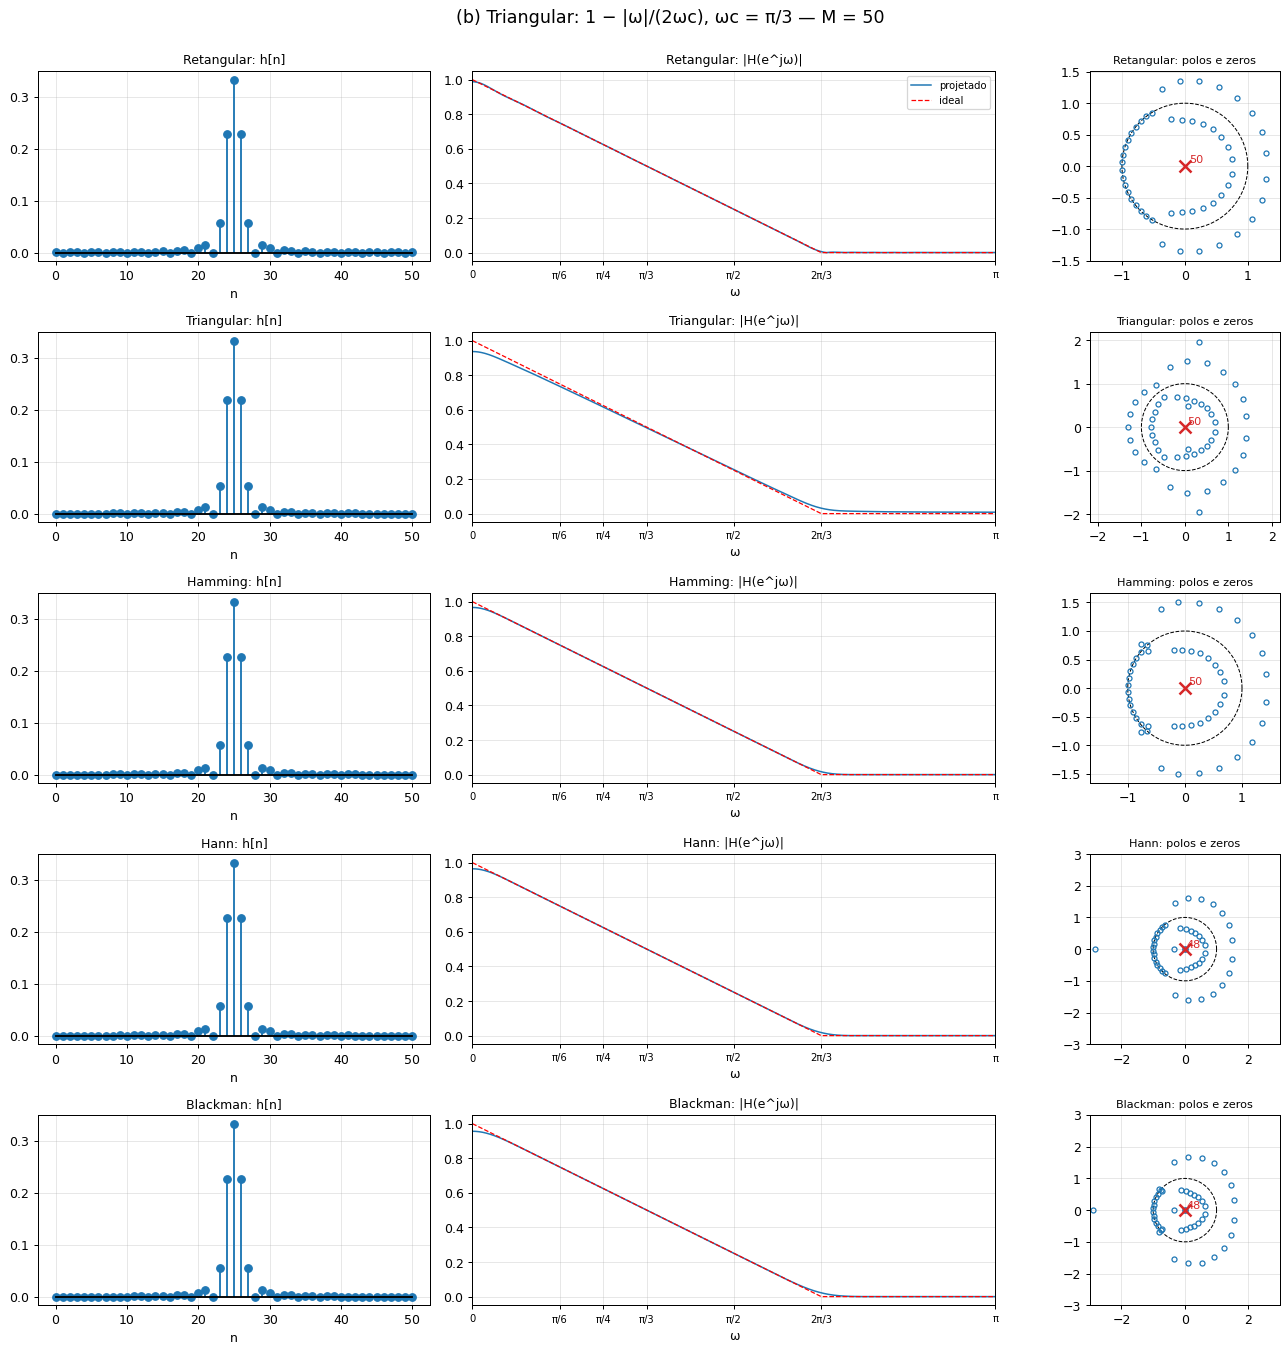

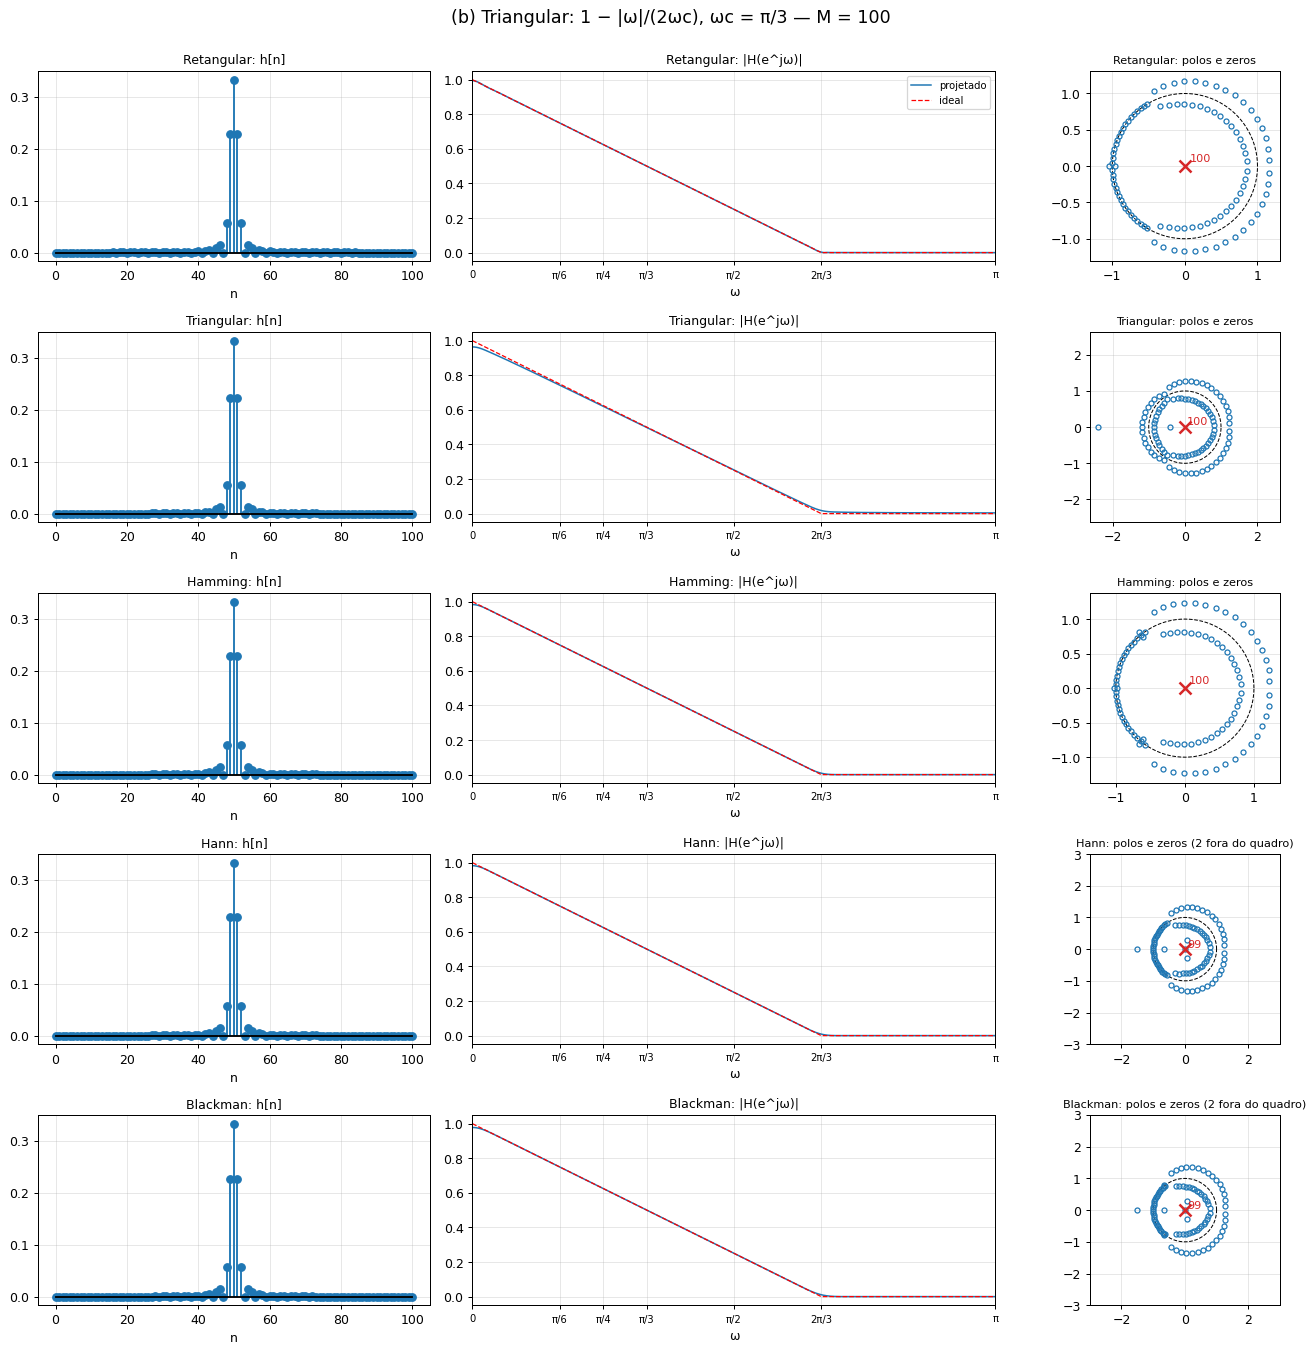

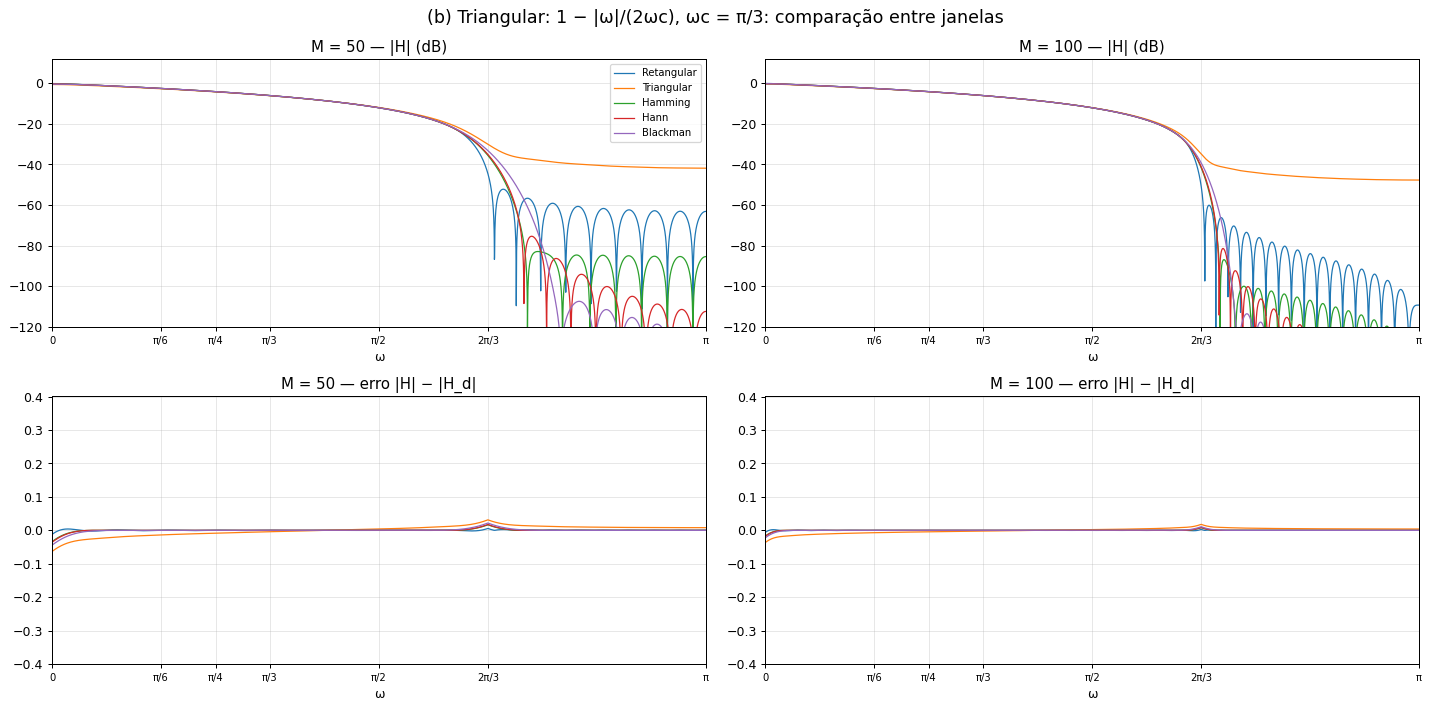

(b) Resultados:


|H| em ω=0  |H| em ω=π/3  |H| em ω=2π/3  |H| em ω=5π/6  \
M   Janela                                                               
50  Retangular       0.988         0.500          0.006          0.001   
    Triangular       0.937         0.496          0.031          0.010   
    Hamming          0.967         0.500          0.017          0.000   
    Hann             0.965         0.500          0.018          0.000   
    Blackman         0.956         0.500          0.022          0.000   
100 Retangular       0.994         0.500          0.003          0.000   
    Triangular       0.964         0.498          0.018          0.005   
    Hamming          0.983         0.500          0.008          0.000   
    Hann             0.982         0.500          0.009          0.000   
    Blackman         0.978         0.500          0.011          0.000   

                Erro máx. (fora das transições)  Rejeição máx. (dB)  
M   Janela                                                           
50  Retangular                            0.012               -59.1  
    Triangular                            0.063               -38.0  
    Hamming                               0.033               -83.0  
    Hann                                  0.035               -81.2  
    Blackman                              0.044               -76.5  
100 Retangular                            0.006               -76.0  
    Triangular                            0.036               -43.9  
    Hamming                               0.017              -101.1  
    Hann                                  0.018              -106.3  
    Blackman                              0.022              -117.7

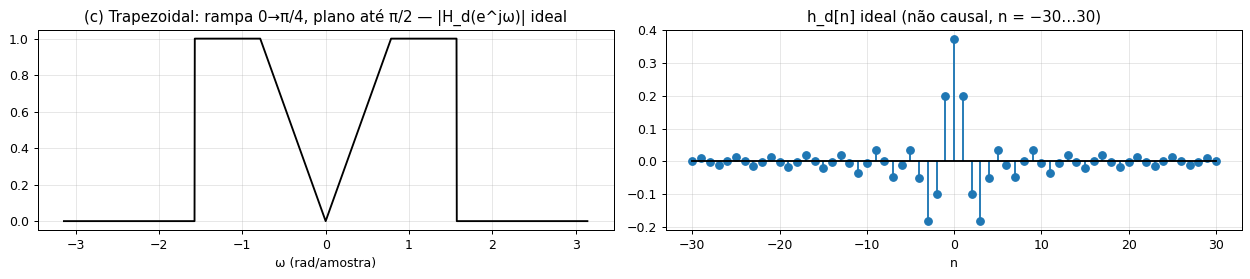

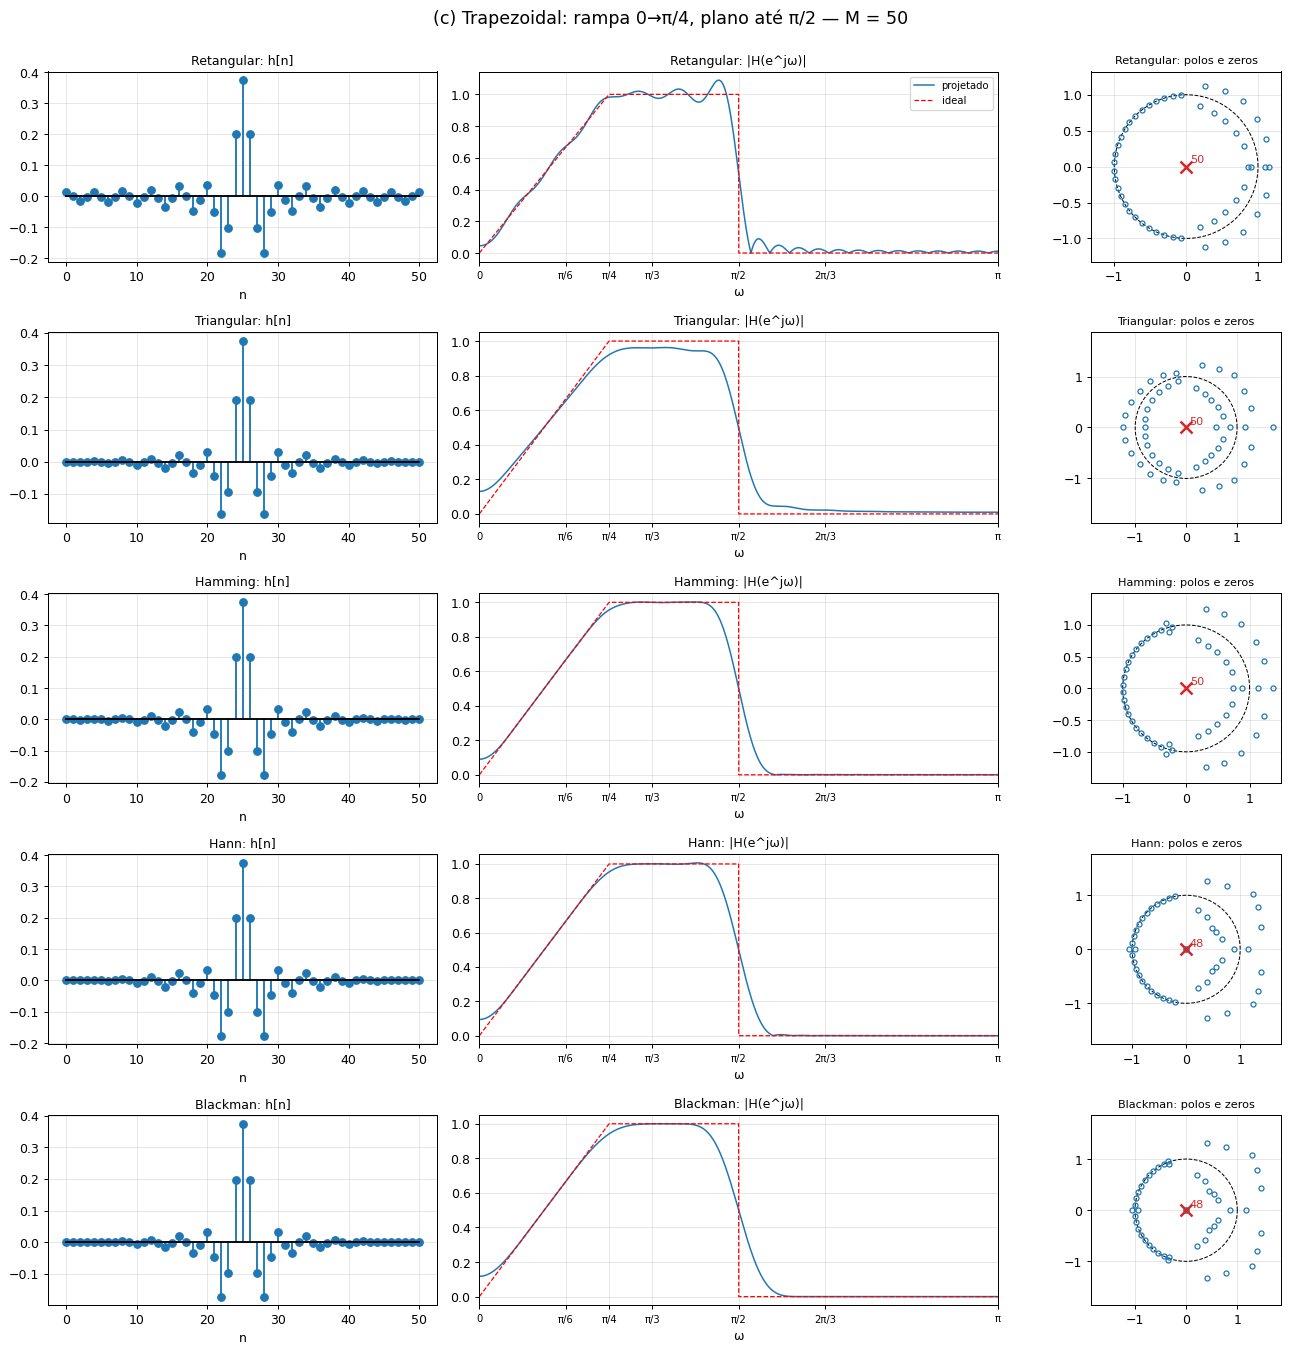

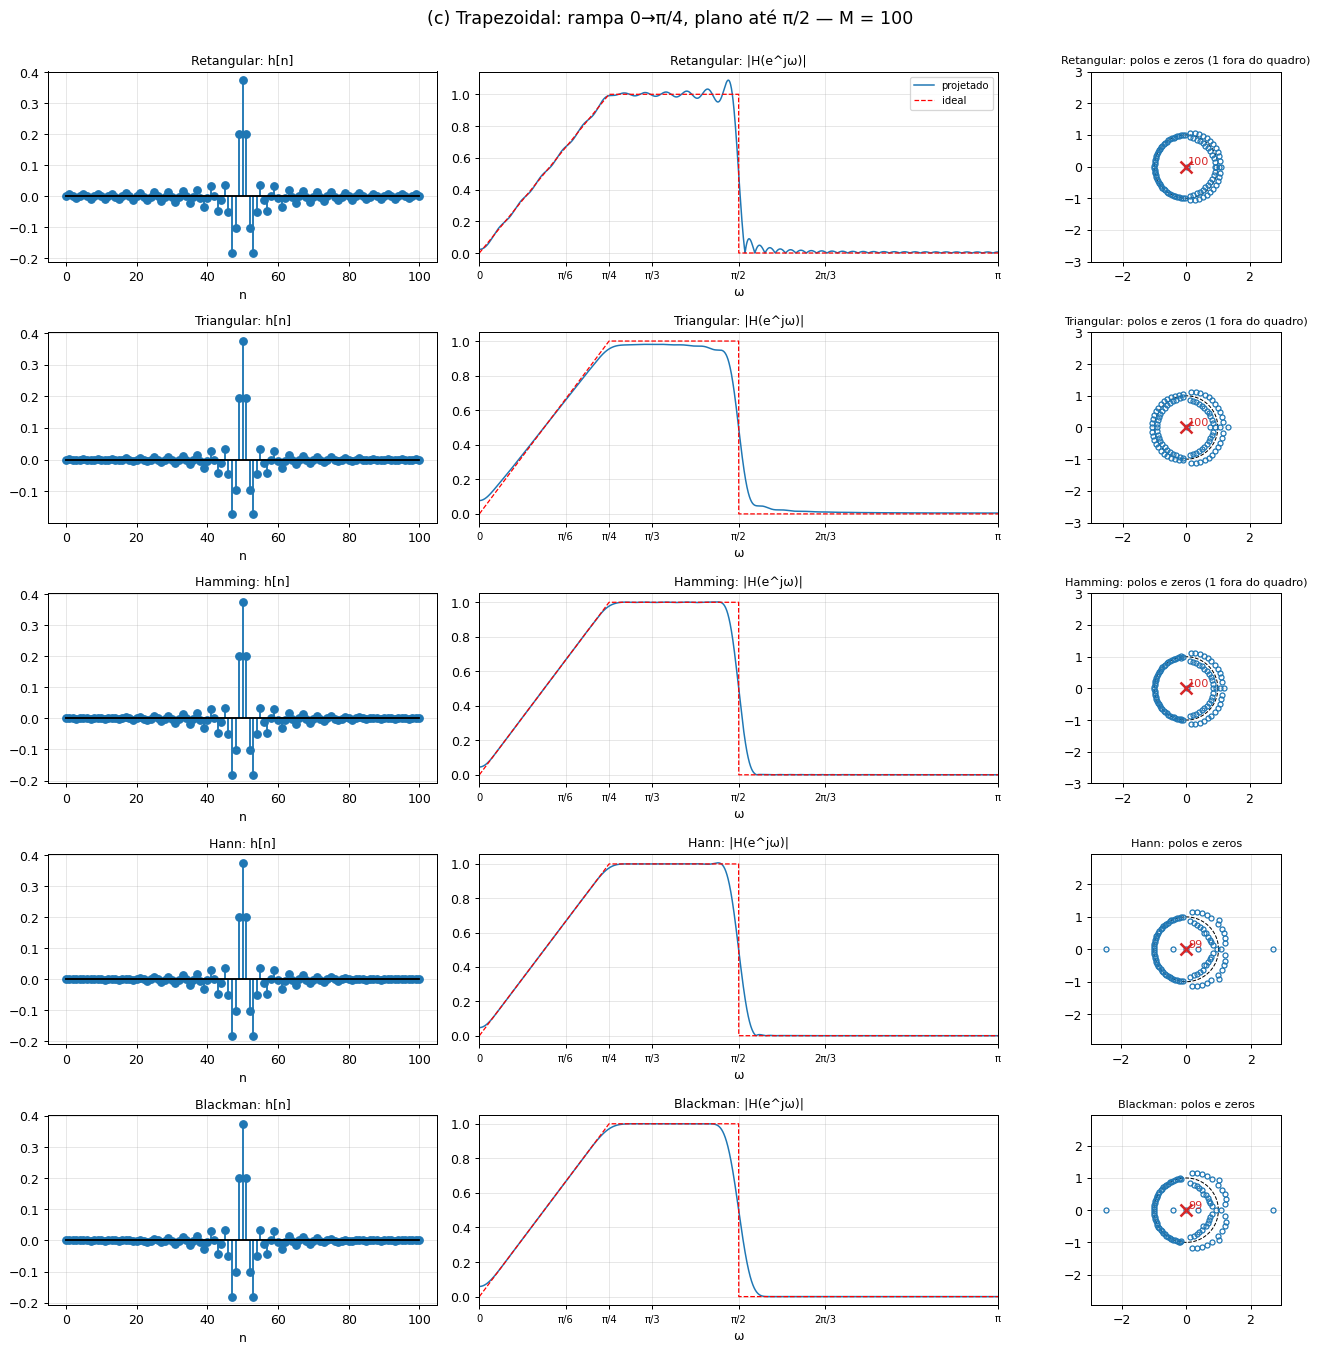

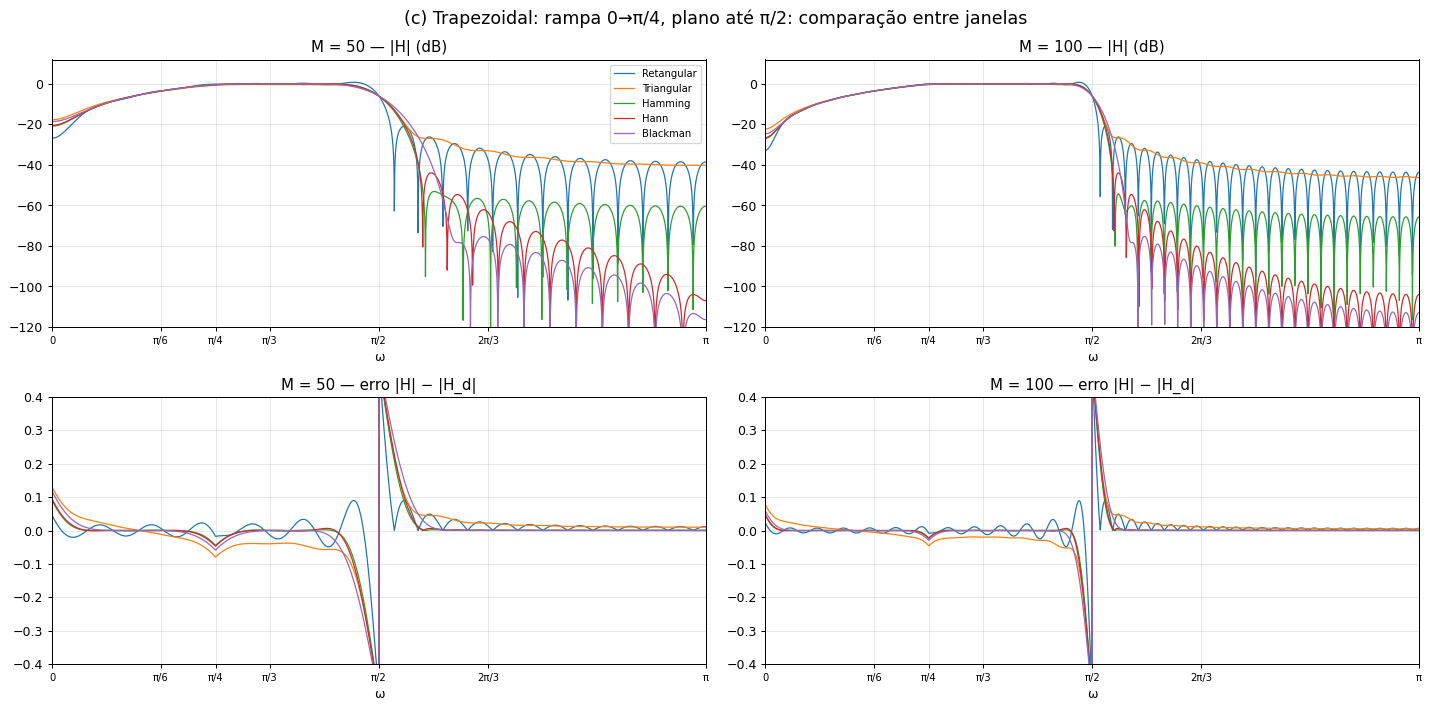

(c) Resultados:


|H| em ω=0  |H| em ω=π/8  |H| em ω=3π/8  |H| em ω=3π/4  \
M   Janela                                                               
50  Retangular       0.045         0.491          1.025          0.001   
    Triangular       0.130         0.503          0.960          0.015   
    Hamming          0.090         0.499          1.000          0.000   
    Hann             0.094         0.500          0.998          0.000   
    Blackman         0.117         0.500          1.000          0.000   
100 Retangular       0.023         0.505          0.988          0.000   
    Triangular       0.077         0.502          0.978          0.008   
    Hamming          0.045         0.500          0.999          0.000   
    Hann             0.047         0.500          1.000          0.000   
    Blackman         0.059         0.500          1.000          0.000   

                Erro máx. (fora das transições)  Rejeição máx. (dB)  
M   Janela                                                           
50  Retangular                            0.048               -26.4  
    Triangular                            0.130               -27.0  
    Hamming                               0.090               -53.1  
    Hann                                  0.094               -43.9  
    Blackman                              0.117               -39.1  
100 Retangular                            0.026               -31.8  
    Triangular                            0.077               -32.7  
    Hamming                               0.045               -57.6  
    Hann                                  0.047               -62.1  
    Blackman                              0.059               -75.3

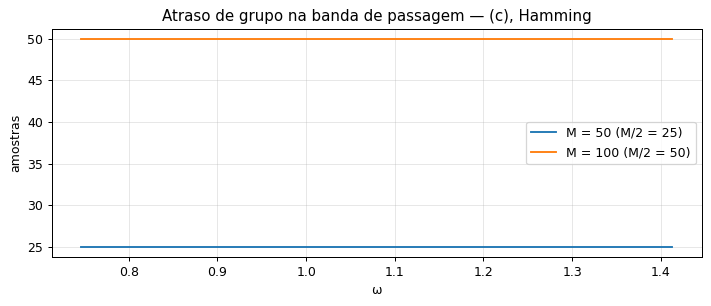

In [ ]:
# ============================================================
# Prática 8 — Questão 2
# Projeto de filtros FIR pelo método das janelas a partir de
# respostas de módulo arbitrárias (implementação própria, sem scipy.signal)
# Ordens: M = 50 e 100
# Janelas: retangular, triangular, Hamming, Hann, Blackman
# Frequência normalizada: w em rad/amostra (w = pi corresponde a ws/2)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display = print

plt.rcParams['figure.dpi'] = 90
ORDENS = [50, 100]

# ---------------------- Janelas ----------------------
def janela_retangular(M):
    return np.ones(M + 1)

def janela_triangular(M):
    # triangular "sem zeros nas pontas": 1 - |n - M/2| / (M/2 + 1)
    n = np.arange(M + 1)
    return 1.0 - np.abs(n - M / 2) / (M / 2 + 1)

def janela_hamming(M):
    n = np.arange(M + 1)
    return 0.54 - 0.46 * np.cos(2 * np.pi * n / M)

def janela_hann(M):
    n = np.arange(M + 1)
    return 0.5 - 0.5 * np.cos(2 * np.pi * n / M)

def janela_blackman(M):
    n = np.arange(M + 1)
    return (0.42 - 0.5 * np.cos(2 * np.pi * n / M)
            + 0.08 * np.cos(4 * np.pi * n / M))

JANELAS = {
    'Retangular': janela_retangular,
    'Triangular': janela_triangular,
    'Hamming': janela_hamming,
    'Hann': janela_hann,
    'Blackman': janela_blackman,
}

# ---------------------- Respostas ideais ----------------------
# h_d[n] = (1/2pi) * integral_{-pi}^{pi} H_d(w) e^{jwn} dw
# Como H_d(w) é real e par, h_d[n] = (1/pi) * integral_0^pi H_d(w) cos(wn) dw.
# O filtro causal usa h_d[n - M/2] (atraso de M/2 amostras -> fase linear).

def _k(M):
    return np.arange(M + 1) - M / 2          # n - M/2

def lp_ideal(k, wc):
    """Passa-baixas ideal de ganho 1: sen(wc k) / (pi k), com limite wc/pi em k = 0."""
    h = np.empty_like(k, dtype=float)
    c = (k == 0)
    h[~c] = np.sin(wc * k[~c]) / (np.pi * k[~c])
    h[c] = wc / np.pi
    return h

# (a) Escada: |H| = 2 em |w| < pi/6, 1 em pi/6 < |w| < pi/3, 0 no resto
#     H_a = PB(pi/3) + PB(pi/6)  ->  h_d[n] = sen(pi n/3)/(pi n) + sen(pi n/6)/(pi n)
def hd_a(M):
    k = _k(M)
    return lp_ideal(k, np.pi / 3) + lp_ideal(k, np.pi / 6)

def H_a(w):
    w = np.abs(w)
    return np.where(w < np.pi / 6, 2.0, np.where(w < np.pi / 3, 1.0, 0.0))

# (b) Triângulo: |H| = 1 - |w| / (2 wc) para |w| < 2 wc, 0 no resto
#     h_d[n] = (1 - cos(2 wc n)) / (2 pi wc n^2),  h_d[0] = wc / pi
#     O enunciado não fixa wc; pela figura, 2wc fica em ~2/3 de ws/2, então wc = pi/3.
WC_B = np.pi / 3

def hd_b(M, wc=WC_B):
    k = _k(M)
    W = 2 * wc
    h = np.empty(M + 1)
    c = (k == 0)
    h[~c] = (1 - np.cos(W * k[~c])) / (np.pi * W * k[~c] ** 2)
    h[c] = W / (2 * np.pi)
    return h

def H_b(w, wc=WC_B):
    w = np.abs(w)
    return np.clip(1 - w / (2 * wc), 0, None)

# (c) Trapézio: rampa de 0 (w = 0) a 1 (w = pi/4), plano até pi/2, 0 depois
#     h_d[n] = (1/pi) [ sen(pi n/2)/n + (cos(a n) - 1)/(a n^2) ],  a = pi/4
#     h_d[0] = (1/pi)(a/2 + pi/4) = 3/8
def hd_c(M):
    k = _k(M)
    a = np.pi / 4
    h = np.empty(M + 1)
    c = (k == 0)
    kk = k[~c]
    h[~c] = (np.sin(np.pi * kk / 2) / kk + (np.cos(a * kk) - 1) / (a * kk ** 2)) / np.pi
    h[c] = 3 / 8
    return h

def H_c(w):
    w = np.abs(w)
    a = np.pi / 4
    return np.where(w < a, w / a, np.where(w <= np.pi / 2, 1.0, 0.0))

FILTROS = {
    'a': ('(a) Escada: 2 até π/6, 1 até π/3', hd_a, H_a),
    'b': ('(b) Triangular: 1 − |ω|/(2ωc), ωc = π/3', hd_b, H_b),
    'c': ('(c) Trapezoidal: rampa 0→π/4, plano até π/2', hd_c, H_c),
}

# Verificação: a expressão analítica bate com a integral numérica da IDTFT?
def hd_numerico(Hfun, M, N=200001):
    w = np.linspace(0, np.pi, N)
    k = _k(M)
    integrando = Hfun(w)[None, :] * np.cos(np.outer(k, w))
    integra = getattr(np, 'trapezoid', None) or np.trapz
    return integra(integrando, w, axis=1) / np.pi

print('Erro máximo entre h_d analítico e h_d numérico (M = 100):')
for chave, (nome, hd, Hf) in FILTROS.items():
    print(f'  {nome}: {np.max(np.abs(hd(100) - hd_numerico(Hf, 100))):.2e}')

# ---------------------- Projeto e análise ----------------------
def projeta_fir(chave, M, nome_janela):
    return FILTROS[chave][1](M) * JANELAS[nome_janela](M)   # h[n] = h_d[n] w[n]

def resposta_frequencia(h, n_pontos=4096):
    """H(e^{jw}) = sum_n h[n] e^{-jwn}, avaliada diretamente em [0, pi]."""
    w = np.linspace(0, np.pi, n_pontos)
    n = np.arange(len(h))
    return w, np.exp(-1j * np.outer(w, n)) @ h

def polos_zeros(h):
    """H(z) = (h0 z^M + ... + hM) / z^M -> zeros = raízes do numerador; M polos em z = 0."""
    M = len(h) - 1
    coef = np.array(h, dtype=float)
    coef[np.abs(coef) < 1e-12 * np.max(np.abs(coef))] = 0.0
    ini = np.argmax(coef != 0)
    fim = len(coef) - np.argmax(coef[::-1] != 0)
    nucleo = coef[ini:fim]
    zeros = np.roots(nucleo) if len(nucleo) > 1 else np.array([])
    zeros = np.concatenate([zeros, np.zeros(len(coef) - fim)])
    polos = np.zeros(M - ini)
    return zeros, polos

def plota_polos_zeros(ax, h, titulo=''):
    zeros, polos = polos_zeros(h)
    t = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(t), np.sin(t), 'k--', lw=0.8)
    ax.plot(zeros.real, zeros.imag, 'o', mfc='none', mec='C0', ms=4, label='zeros')
    if len(polos):
        ax.plot(0, 0, 'x', color='C3', ms=9, mew=2, label='polos')
        ax.annotate(f'{len(polos)}', (0.06, 0.06), color='C3', fontsize=9)
    lim = min(max(1.3, 1.1 * np.max(np.abs(zeros)) if len(zeros) else 1.3), 3.0)
    fora = np.sum(np.abs(zeros) > lim)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect('equal'); ax.grid(alpha=0.3)
    ax.set_title(titulo + (f' ({fora} fora do quadro)' if fora else ''), fontsize=9)

def eixo_pi(ax):
    ax.set_xticks([0, np.pi / 6, np.pi / 4, np.pi / 3, np.pi / 2, 2 * np.pi / 3, np.pi])
    ax.set_xticklabels(['0', 'π/6', 'π/4', 'π/3', 'π/2', '2π/3', 'π'], fontsize=8)

def plota_ideal(chave):
    nome, hd, Hf = FILTROS[chave]
    fig, axs = plt.subplots(1, 2, figsize=(14, 3.2))
    w = np.linspace(-np.pi, np.pi, 2001)
    axs[0].plot(w, Hf(w), 'k', lw=1.5)
    axs[0].set_title(f'{nome} — |H_d(e^jω)| ideal'); axs[0].set_xlabel('ω (rad/amostra)'); axs[0].grid(alpha=0.3)
    k = np.arange(-30, 31)
    hk = hd(60)
    axs[1].stem(k, hk, basefmt='k-')
    axs[1].set_title('h_d[n] ideal (não causal, n = −30…30)'); axs[1].set_xlabel('n'); axs[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

def painel_filtro(chave, M):
    nome, hd, Hf = FILTROS[chave]
    fig, axs = plt.subplots(len(JANELAS), 3, figsize=(15, 3.0 * len(JANELAS)),
                            gridspec_kw={'width_ratios': [1.2, 1.6, 0.9]})
    for i, nj in enumerate(JANELAS):
        h = projeta_fir(chave, M, nj)
        w, H = resposta_frequencia(h)
        ax = axs[i, 0]
        ax.stem(np.arange(M + 1), h, basefmt='k-')
        ax.set_title(f'{nj}: h[n]', fontsize=10); ax.set_xlabel('n'); ax.grid(alpha=0.3)
        ax = axs[i, 1]
        ax.plot(w, np.abs(H), lw=1.2, label='projetado')
        ax.plot(w, Hf(w), 'r--', lw=1, label='ideal')
        ax.set_xlim(0, np.pi); eixo_pi(ax)
        ax.set_title(f'{nj}: |H(e^jω)|', fontsize=10); ax.set_xlabel('ω'); ax.grid(alpha=0.3)
        if i == 0: ax.legend(fontsize=8)
        plota_polos_zeros(axs[i, 2], h, f'{nj}: polos e zeros')
    fig.suptitle(f'{nome} — M = {M}', fontsize=14, y=1.0)
    fig.tight_layout(); plt.show()

def compara_janelas(chave):
    nome, hd, Hf = FILTROS[chave]
    fig, axs = plt.subplots(2, len(ORDENS), figsize=(16, 8))
    for j, M in enumerate(ORDENS):
        for nj in JANELAS:
            w, H = resposta_frequencia(projeta_fir(chave, M, nj))
            axs[0, j].plot(w, 20 * np.log10(np.abs(H) + 1e-12), lw=1, label=nj)
            axs[1, j].plot(w, np.abs(H) - Hf(w), lw=1, label=nj)
        axs[0, j].set_ylim(-120, 12); axs[0, j].set_title(f'M = {M} — |H| (dB)')
        axs[1, j].set_ylim(-0.4, 0.4); axs[1, j].set_title(f'M = {M} — erro |H| − |H_d|')
        for ax in axs[:, j]:
            ax.set_xlim(0, np.pi); eixo_pi(ax); ax.grid(alpha=0.3); ax.set_xlabel('ω')
    axs[0, 0].legend(fontsize=8)
    fig.suptitle(f'{nome}: comparação entre janelas', fontsize=14)
    fig.tight_layout(); plt.show()

def tabela(chave, pontos):
    """Ganho |H| (linear) em frequências de teste + erro máximo e atenuação na banda de rejeição."""
    nome, hd, Hf = FILTROS[chave]
    linhas = {}
    for M in ORDENS:
        for nj in JANELAS:
            h = projeta_fir(chave, M, nj)
            n = np.arange(M + 1)
            g = [abs(np.sum(h * np.exp(-1j * p * n))) for _, p in pontos]
            w, H = resposta_frequencia(h)
            erro = np.abs(np.abs(H) - Hf(w))
            # banda de rejeição "longe" do corte (> 0.25 rad depois de onde H_d zera)
            corte = {'a': np.pi / 3, 'b': 2 * WC_B, 'c': np.pi / 2}[chave]
            longe = w > corte + 0.25
            linha = {f'|H| em {r}': round(v, 3) for (r, _), v in zip(pontos, g)}
            linha['Erro máx. (fora das transições)'] = round(np.max(erro[transicao_ok(chave, w)]), 3)
            linha['Rejeição máx. (dB)'] = round(20 * np.log10(np.max(np.abs(H[longe])) + 1e-15), 1)
            linhas[(M, nj)] = linha
    df = pd.DataFrame(linhas).T
    df.index.names = ['M', 'Janela']
    return df

def transicao_ok(chave, w, d=0.25):
    """Máscara que exclui uma vizinhança de ±d rad em torno das descontinuidades de H_d."""
    desc = {'a': [np.pi / 6, np.pi / 3], 'b': [], 'c': [np.pi / 2]}[chave]
    m = np.ones_like(w, dtype=bool)
    for x in desc:
        m &= np.abs(w - x) > d
    return m

# ==================== Janelas usadas ====================
fig, ax = plt.subplots(figsize=(8, 3.5))
for nj, jan in JANELAS.items():
    ax.plot(np.arange(51), jan(50), '.-', label=nj)
ax.set_title('Janelas no tempo (M = 50)'); ax.set_xlabel('n'); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

# ==================== (a) ====================
plota_ideal('a')
for M in ORDENS:
    painel_filtro('a', M)
compara_janelas('a')
print('(a) Resultados:')
display(tabela('a', [('ω=0', 0), ('ω=π/12', np.pi / 12), ('ω=π/4', np.pi / 4), ('ω=π/2', np.pi / 2)]))

# ==================== (b) ====================
plota_ideal('b')
for M in ORDENS:
    painel_filtro('b', M)
compara_janelas('b')
print('(b) Resultados:')
display(tabela('b', [('ω=0', 0), ('ω=π/3', np.pi / 3), ('ω=2π/3', 2 * np.pi / 3), ('ω=5π/6', 5 * np.pi / 6)]))

# ==================== (c) ====================
plota_ideal('c')
for M in ORDENS:
    painel_filtro('c', M)
compara_janelas('c')
print('(c) Resultados:')
display(tabela('c', [('ω=0', 0), ('ω=π/8', np.pi / 8), ('ω=3π/8', 3 * np.pi / 8), ('ω=3π/4', 3 * np.pi / 4)]))

# ==================== Fase linear ====================
fig, ax = plt.subplots(figsize=(8, 3.5))
for M in ORDENS:
    w, H = resposta_frequencia(projeta_fir('c', M, 'Hamming'))
    fase = np.unwrap(np.angle(H))
    tau = -np.diff(fase) / np.diff(w)
    banda = (w[:-1] > 0.95 * np.pi / 4) & (w[:-1] < 0.9 * np.pi / 2)
    ax.plot(w[:-1][banda], tau[banda], label=f'M = {M} (M/2 = {M // 2})')
ax.set_title('Atraso de grupo na banda de passagem — (c), Hamming'); ax.set_xlabel('ω'); ax.set_ylabel('amostras')
ax.grid(alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()

## Comentários sobre os resultados

**Respostas ao impulso ideais.** Como os três módulos são reais e pares, $h_d[n] = \frac{1}{\pi}\int_0^{\pi} H_d(\omega)\cos(\omega n)\,d\omega$ (usando $n - M/2$ para tornar o filtro causal, com atraso de $M/2$ amostras):

- (a) Escada = soma de dois passa-baixas ideais (cortes em $\pi/3$ e $\pi/6$): $h_d[n] = \dfrac{\operatorname{sen}(\pi n/3) + \operatorname{sen}(\pi n/6)}{\pi n}$, com $h_d[0] = 1/2$.
- (b) Triangular com zero em $2\omega_c$: $h_d[n] = \dfrac{1-\cos(2\omega_c n)}{2\pi\omega_c n^2}$, com $h_d[0] = \omega_c/\pi$. Como o enunciado não fixa $\omega_c$, adotou-se $\omega_c = \pi/3$ (pela figura, $2\omega_c$ fica em cerca de 2/3 de $\omega_s/2$).
- (c) Trapezoidal (rampa de 0 a $\pi/4$, plano até $\pi/2$): $h_d[n] = \dfrac{1}{\pi}\left[\dfrac{\operatorname{sen}(\pi n/2)}{n} + \dfrac{\cos(\pi n/4)-1}{(\pi/4)\,n^2}\right]$, com $h_d[0] = 3/8$.

As três expressões foram conferidas com a integral numérica da IDTFT (erro da ordem de $10^{-6}$ ou menor).

**(a) Escada.** Por ter dois degraus (descontinuidades em $\pi/6$ e $\pi/3$), $h_d[n]$ decai só com $1/n$, e o truncamento gera oscilações de Gibbs nos dois degraus. Com a janela retangular, o erro fora das transições fica em torno de 0,07 (M = 50) e a rejeição máxima após $\pi/3$ é de apenas ≈ −23 dB (M = 50) e ≈ −31 dB (M = 100). As janelas Hamming, Hann e Blackman praticamente eliminam o ripple (erro ≈ 0,01 ou menor) e reproduzem bem os níveis 2 e 1. Com M = 100, a rejeição chega a ≈ −55 dB (Hamming), −62 dB (Hann) e −75 dB (Blackman). Em troca, os degraus ficam mais "arredondados" (transições mais largas), principalmente na Blackman. Dobrar M estreita essas transições.

**(b) Triangular.** Aqui $H_d$ é contínua, então $h_d[n]$ decai com $1/n^2$ e o truncamento quase não causa Gibbs. Por isso a janela retangular é a melhor nesse caso: $|H(0)| ≈ 0{,}99$ e erro máximo ≈ 0,01 (M = 50). As demais janelas só suavizam ainda mais o pico em ω = 0 (ex.: 0,96 na Hamming e na Blackman), e a triangular é a pior (0,94). Em todas, o ganho em $\omega_c = \pi/3$ fica exatamente em 0,5, como no ideal. A rejeição após $2\omega_c$ é muito alta: mais de −75 dB nas janelas suaves com M = 50, e mais de −100 dB com M = 100. Aumentar M reduz o erro nas "quinas" do triângulo (ω = 0 e ω = $2\omega_c$).

**(c) Trapezoidal.** A rampa é contínua, mas há um degrau em $\pi/2$, que domina o comportamento. A janela retangular dá ripple de ≈ 2,5% no patamar e rejeição de ≈ −26 dB (M = 50) / −32 dB (M = 100). Hamming, Hann e Blackman deixam o patamar plano (|H| ≈ 1,000) e a rejeição chega a −53 a −75 dB. O maior erro aparece em ω = 0, onde a "quina" da rampa é suavizada e o filtro não chega a zero (|H(0)| ≈ 0,09 com Hamming e M = 50). Esse erro cai pela metade ao passar para M = 100. No meio da rampa (ω = π/8), todas as janelas acertam o valor ideal 0,5.

**Polos e zeros.** Todos os filtros são FIR: os polos ficam todos em z = 0 (M polos, ou menos na Hann e na Blackman, que zeram as pontas). Portanto, são sempre estáveis. Os zeros aparecem em pares recíprocos ($z_0$ e $1/z_0^*$), o que é consequência da simetria $h[n] = h[M-n]$. Os zeros sobre a circunferência unitária ficam concentrados nas bandas de rejeição (ω > π/3 em (a), ω > 2π/3 em (b) e ω > π/2 em (c)). Os zeros dentro e fora da circunferência moldam a banda de passagem.

**Fase linear.** Como todo $h[n]$ é simétrico, a fase é linear e o atraso de grupo é constante e igual a $M/2$ (25 e 50 amostras), como mostra o último gráfico.

**Conclusão.** Vale o mesmo compromisso da Questão 1: janelas suaves (Hamming, Hann, Blackman) reduzem muito o Gibbs e aumentam a rejeição, mas alargam as transições, enquanto aumentar M estreita as transições. A diferença é que a melhor janela depende da resposta desejada. Quando $H_d$ tem descontinuidades (a, c), as janelas suaves são claramente melhores. Quando $H_d$ é contínua (b), o truncamento já é pouco prejudicial, e a janela retangular, que é a que menos distorce, dá o menor erro.